In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("cleaned_new_df.csv")
df['Year']=df['Year'].astype(int)
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16286,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16287,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16288,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16289,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


Insight: NA dominates, EU follows, JP and Other are weaker


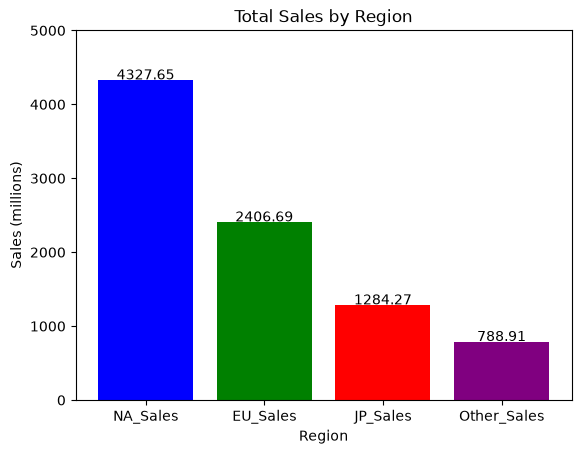

In [2]:
#1. Regional Sales Comparison
'''
i → x‑position (bar index).

value + 5 → y‑position (slightly above bar height).

round(value, 2) → text string (the actual number).

ha='center' → center the text above the bar.

So the bar stays at value, but the text is placed at value+5 (just above).

Seaborn → use palette for multiple colors.
Matplotlib (plt.bar) → use color with a list of colors.

'''
total_NA_Sales=df['NA_Sales'].sum()
total_EU_Sales=df['EU_Sales'].sum()
total_JP_Sales=df['JP_Sales'].sum()
total_Other_Sales=df['Other_Sales'].sum()
x_axis=['NA_Sales','EU_Sales','JP_Sales','Other_Sales']
plt.bar(x_axis,[total_NA_Sales, total_EU_Sales, total_JP_Sales, total_Other_Sales],color=['Blue','Green','Red','Purple'])
for i, value in enumerate([total_NA_Sales, total_EU_Sales, total_JP_Sales, total_Other_Sales]):
    plt.text(i, value+10, round(value, 2),ha='center')
plt.ylim(0,5000)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel('Sales (millions)')
print('Insight: NA dominates, EU follows, JP and Other are weaker')
plt.show()


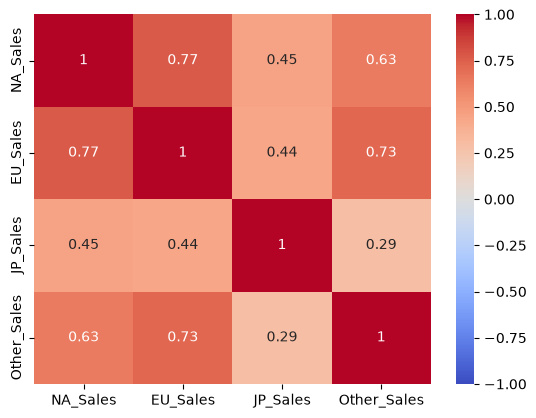

In [3]:
#2. Correlation Heatmap
corr_matrix=df[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].corr()
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',vmin=-1,vmax=1) 
plt.show()

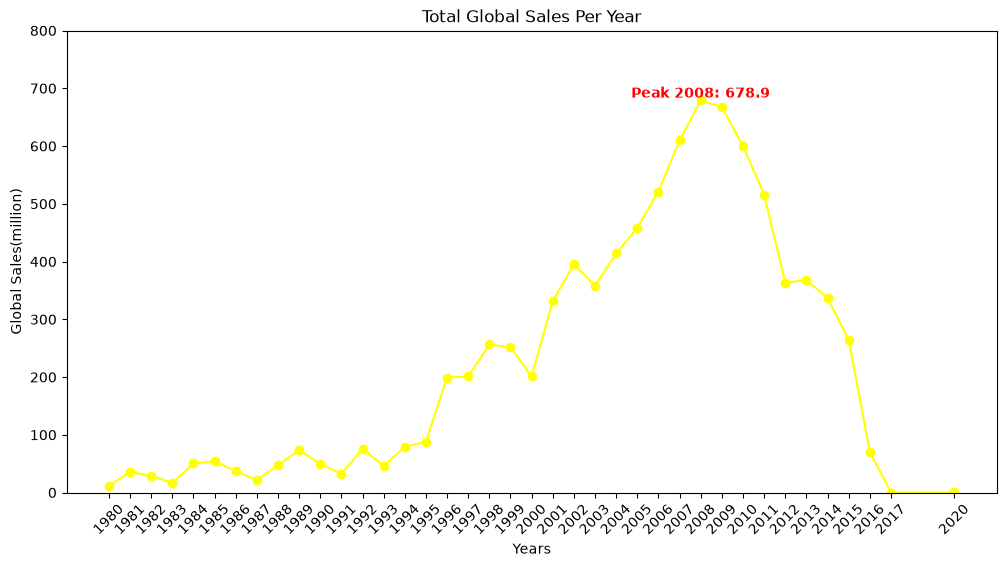

In [4]:
#3. Trend Over Years
# Goal: Show sales over time.
plt.figure(figsize=(12,6))
year_sales=df.groupby('Year')['Global_Sales'].sum().sort_index()
plt.plot(year_sales.index,year_sales,marker='o',color='Yellow')
peak_year = year_sales.idxmax()
peak_value = year_sales.max()
plt.text(peak_year, peak_value+5, 
         f"Peak {peak_year}: {round(peak_value,2)}", 
         ha='center', color='red', fontweight='bold')

plt.xlabel("Years")
plt.ylabel("Global Sales(million)")
plt.ylim(0,800)
plt.title("Total Global Sales Per Year")
plt.xticks(year_sales.index,rotation=45,ha='center')
plt.show()



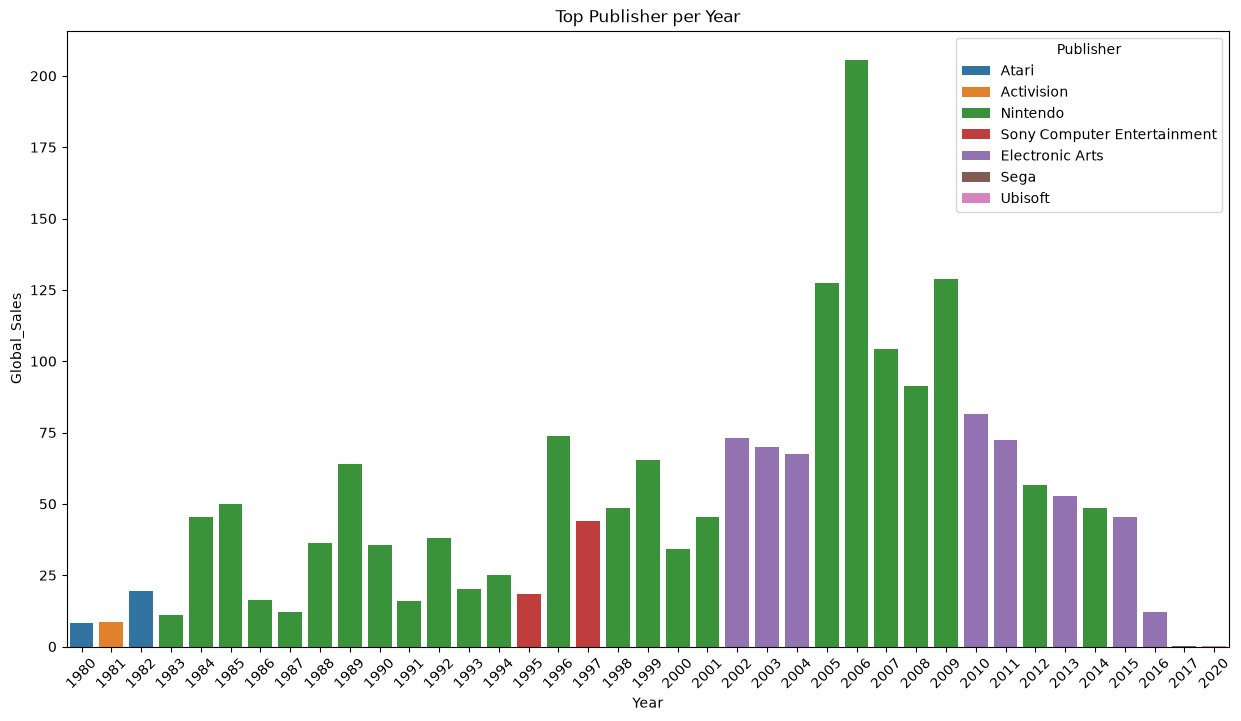

In [5]:
#4: Top Publishers Each Year
# Find the publisher with the highest sales per year.
publishers_year_sales = df.groupby(['Year','Publisher'])['Global_Sales'] .sum().reset_index() #reset index convert the index back to dataframe
top_per_year=publishers_year_sales.loc[publishers_year_sales.groupby('Year')["Global_Sales"].idxmax()]
plt.figure(figsize=(15,8))
sns.barplot(x='Year', y='Global_Sales',data=top_per_year, hue='Publisher')
plt.title("Top Publisher per Year")
plt.xticks(rotation=45)
plt.show()

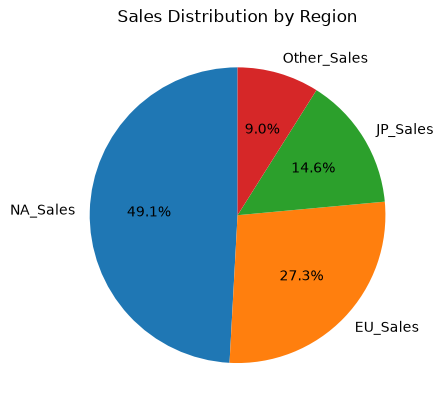

'\nNorth America contributes the largest share of global sales.\n\nEurope is the second strongest region.\n\nJapan has smaller share compared to NA/EU.\n\nOther regions contribute a small percentage.\n'

In [6]:
#5. Sales by Region
total_NA_Sales=df['NA_Sales'].sum()
total_EU_Sales=df['EU_Sales'].sum()
total_JP_Sales=df['JP_Sales'].sum()
total_Other_Sales=df['Other_Sales'].sum()
regions=['NA_Sales','EU_Sales','JP_Sales','Other_Sales']
plt.pie([total_NA_Sales,total_EU_Sales,total_JP_Sales,total_Other_Sales],labels=regions,autopct="%1.1f%%",startangle=90)
plt.title("Sales Distribution by Region")

plt.show()

'''
North America contributes the largest share of global sales.

Europe is the second strongest region.

Japan has smaller share compared to NA/EU.

Other regions contribute a small percentage.
'''